# Case Study 20 — Did the New Approval Policy Hurt Approval Rates?

**Simpson's paradox · aggregation bias · composition (mix) effects · exact decomposition of a change into "rate" and
"mix" parts · direct standardisation · stratified analysis (Mantel-Haenszel, Cochran-Mantel-Haenszel, Breslow-Day) ·
logistic regression adjustment · causal diagrams: when to stratify and when not to**

| | |
|---|---|
| **Domain** | Retail lending: credit policy |
| **Stakeholders** | Chief Risk Officer, Head of Credit Policy, Head of Acquisition |
| **Difficulty** | Intermediate |
| **Importance** | 🟠 SHOULD GO THROUGH |
| **Builds on** | Case 02 (rates and odds ratios), Case 05 and 08 (third variables, confounding) |
| **Data** | 27,000 personal-loan applications: 12,000 before and 15,000 after a policy change |

> **This dataset is synthetic** and was generated to reproduce a realistic business scenario. It is not actual
> customer data. See `src/generate_data.py`.

**What you will learn**

1. How an overall comparison can **reverse** once you look within groups (Simpson's paradox), and why it happens.
2. How to **decompose** a change in an overall rate into "what happened within groups" and "who is in the groups".
3. How to compute a **fair comparison** (standardised rate, Mantel-Haenszel odds ratio, adjusted regression).
4. Why **which comparison is right** depends on the **causal story**, not on a statistical rule.

## Section 1 — Business context

In April, the lender replaced its personal-loan approval policy. The Chief Risk Officer opens the quarterly report:

> *"Overall approval fell from about 70% to about 66% after the new policy. Credit Policy swears the new rules are
> more generous at every risk level. Which is it? Did we just make approvals harder? And separately, our agent-network
> acquisition campaign started in April. Does that matter?"*

Each application carries an **application scorecard risk band** (A = lowest risk … D = highest risk), the **channel**
it came through (Branch, Online, Agent), the **period** (before or after the policy change), and the **decision**.

## Section 2 — Business questions

1. Did the overall approval rate fall, and by how much?
2. Did approval rates change **within** risk bands?
3. Why do the overall and within-band answers disagree?
4. Which comparison answers the Chief Risk Officer's question: "is the new policy stricter?"
5. What should be reported, and what does this analysis **not** show?

## Section 3 — Statistical translation

| # | Business question | Statistical question | Method |
|---|---|---|---|
| 1 | Overall change? | Difference of two proportions (risk difference, odds ratio) | z-test, CI |
| 2 | Within bands? | The same, **per risk band** | Stratified tables, forest plot |
| 3 | Why different? | How much of the overall change is due to a **change in mix**? | Exact decomposition: within-band (rate) effect + composition (mix) effect |
| 4 | Fair comparison? | Rate difference **at a fixed risk mix** | Direct standardisation; Mantel-Haenszel; logistic regression with risk band |
| 5 | Causal story | What caused the mix shift? Is it a confounder or a consequence of the policy? | Channel analysis, causal diagram |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import StratifiedTable

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "00_shared_resources").is_dir())
sys.path.insert(0, str(ROOT / "00_shared_resources"))
from utils import case_paths, save_table, fmt_p, rng_for_case
from statistical_tests import proportion_ci
from plotting import set_style, save_fig, add_note, COLORS, CATEGORICAL, PRIMARY, HIGHLIGHT, INK, INK_MUTED

CASE_DIR = ROOT / "case_studies" / "20_simpsons_paradox_approvals"
PATHS = case_paths(CASE_DIR)
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
rng = rng_for_case(2020)
pctfmt = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
BANDS = ["A", "B", "C", "D"]
BEFORE, AFTER = COLORS["blue"], COLORS["orange"]

def wilson(k, n):
    ci = proportion_ci(int(k), int(n))
    return ci["lower"], ci["upper"]

def diff_ci(k1, n1, k0, n0):
    # Wald CI for p1 − p0 (after − before).
    p1, p0 = k1 / n1, k0 / n0
    se = np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
    return p1 - p0, p1 - p0 - 1.96 * se, p1 - p0 + 1.96 * se

## Section 4 — Load the data

In [2]:
apps = pd.read_csv(PATHS["data"] / "loan_applications.csv")
print(f"{len(apps):,} applications × {apps.shape[1]} columns;  duplicates: {apps['app_id'].duplicated().sum()};  missing: {apps.isna().sum().sum()}")
display(apps.head())
apps["risk_band"] = pd.Categorical(apps["risk_band"], categories=BANDS, ordered=True)
apps["channel"] = pd.Categorical(apps["channel"], categories=["Branch", "Online", "Agent"])
apps["after"] = (apps["period"] == "After").astype(int)
display(pd.crosstab(apps["period"], apps["approved"], margins=True))

27,000 applications × 5 columns;  duplicates: 0;  missing: 0


,app_id,period,channel,risk_band,approved
0,LA20100000,Before,Branch,B,0
1,LA20100001,Before,Branch,A,1
2,LA20100002,Before,Branch,B,1
3,LA20100003,Before,Branch,A,0
4,LA20100004,Before,Online,B,1


approved,0,1,All
period,,,
After,5146,9854,15000
Before,3650,8350,12000
All,8796,18204,27000


## Section 5 — The overall comparison

In [3]:
g = apps.groupby("period")["approved"].agg(["sum", "size"])
k0, n0 = g.loc["Before"]; k1, n1 = g.loc["After"]
d_, lo_, hi_ = diff_ci(k1, n1, k0, n0)
z_ = (k1 / n1 - k0 / n0) / np.sqrt((k1 + k0) / (n1 + n0) * (1 - (k1 + k0) / (n1 + n0)) * (1 / n1 + 1 / n0))
p_ = 2 * stats.norm.sf(abs(z_))
or_ = (k1 / (n1 - k1)) / (k0 / (n0 - k0))
se_or = np.sqrt(1 / k1 + 1 / (n1 - k1) + 1 / k0 + 1 / (n0 - k0))
overall = pd.DataFrame({"estimate": [k0 / n0, k1 / n1, 100 * d_, (k1 / n1) / (k0 / n0), or_],
                        "ci_low": [wilson(k0, n0)[0], wilson(k1, n1)[0], 100 * lo_, np.nan, np.exp(np.log(or_) - 1.96 * se_or)],
                        "ci_high": [wilson(k0, n0)[1], wilson(k1, n1)[1], 100 * hi_, np.nan, np.exp(np.log(or_) + 1.96 * se_or)]},
                       index=["approval rate before", "approval rate after", "difference (percentage points)", "risk ratio", "odds ratio"])
save_table(overall, "overall_comparison", PATHS["tables"])
display(overall)
print(f"z = {z_:.1f}, p = {fmt_p(p_)}  → overall approval FELL by {-100 * d_:.1f} points")

,estimate,ci_low,ci_high
approval rate before,0.6958,0.6875,0.7040
approval rate after,0.6569,0.6493,0.6645
difference (percentage points),-3.8900,-5.0102,-2.7698
risk ratio,0.9441,NaN,NaN
odds ratio,0.8370,0.7951,0.8813


z = -6.8, p = < 0.001  → overall approval FELL by 3.9 points


**Observation.** Overall approval fell from **69.6%** to **65.7%**: a **drop of 3.9 percentage points** (95% CI about
−5.0 to −2.8; odds ratio about 0.84, p < 0.001). On this evidence alone, the new policy looks stricter.

## Section 6 — Within risk bands

In [4]:
rows = []
for b in BANDS:
    s = apps[apps["risk_band"] == b]
    a = s[s["period"] == "After"]["approved"]; bf = s[s["period"] == "Before"]["approved"]
    d, lo, hi = diff_ci(a.sum(), len(a), bf.sum(), len(bf))
    pooled = (a.sum() + bf.sum()) / (len(a) + len(bf))
    z = d / np.sqrt(pooled * (1 - pooled) * (1 / len(a) + 1 / len(bf)))
    rows.append({"risk band": b, "applications before": len(bf), "applications after": len(a), "approval before": bf.mean(), "approval after": a.mean(),
                 "difference (pp)": 100 * d, "ci_low (pp)": 100 * lo, "ci_high (pp)": 100 * hi, "p_value": 2 * stats.norm.sf(abs(z))})
byband = pd.DataFrame(rows).set_index("risk band")
save_table(byband, "by_risk_band", PATHS["tables"])
display(byband)

,applications before,applications after,approval before,approval after,difference (pp),ci_low (pp),ci_high (pp),p_value
risk band,,,,,,,,
A,5330,4626,0.8992,0.9505,5.1248,4.1031,6.1464,0.0000
B,3768,4387,0.6951,0.7588,6.3769,4.4370,8.3169,0.0000
C,1993,3579,0.4009,0.4579,5.7046,3.0039,8.4053,0.0000
D,909,2408,0.1529,0.2031,5.0158,2.1775,7.8541,0.0010


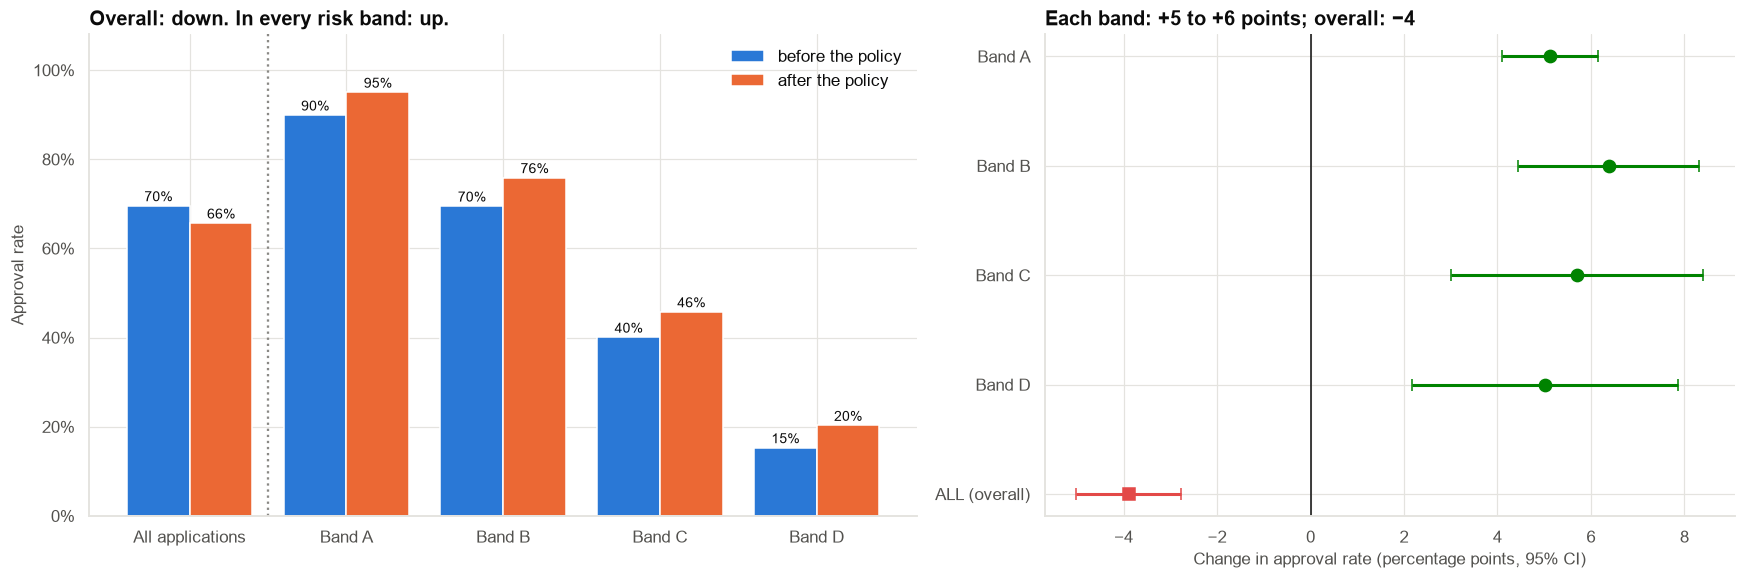

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.4), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
labels = ["ALL", *BANDS]
x = np.arange(len(labels))
before_v = [k0 / n0, *byband["approval before"]]; after_v = [k1 / n1, *byband["approval after"]]
ax.bar(x - 0.2, before_v, width=0.4, color=BEFORE, label="before the policy")
ax.bar(x + 0.2, after_v, width=0.4, color=AFTER, label="after the policy")
for xi, bv, av in zip(x, before_v, after_v):
    ax.text(xi - 0.2, bv + 0.01, f"{bv:.0%}", ha="center", fontsize=9); ax.text(xi + 0.2, av + 0.01, f"{av:.0%}", ha="center", fontsize=9)
ax.set_xticks(x, ["All applications", *[f"Band {b}" for b in BANDS]]); ax.yaxis.set_major_formatter(pctfmt)
ax.axvline(0.5, color=INK_MUTED, ls=":")
ax.set(ylabel="Approval rate", title="Overall: down. In every risk band: up.", ylim=(0, 1.08))
ax.legend(frameon=False, loc="upper right")
ax = axes[1]
yy = np.arange(len(BANDS))[::-1]
for yi, b in zip(yy, BANDS):
    r = byband.loc[b]
    ax.errorbar(r["difference (pp)"], yi, xerr=[[r["difference (pp)"] - r["ci_low (pp)"]], [r["ci_high (pp)"] - r["difference (pp)"]]], fmt="o", color=COLORS["green"], ms=8, capsize=4, lw=2)
ax.errorbar(100 * d_, -1, xerr=[[100 * (d_ - lo_)], [100 * (hi_ - d_)]], fmt="s", color=COLORS["red"], ms=8, capsize=4, lw=2)
ax.set_yticks(list(yy) + [-1], [f"Band {b}" for b in BANDS] + ["ALL (overall)"]); ax.axvline(0, color=INK, lw=1)
ax.set(xlabel="Change in approval rate (percentage points, 95% CI)", title="Each band: +5 to +6 points; overall: −4")
fig.tight_layout()
save_fig(fig, "fig01_the_paradox", PATHS["figures"])
plt.show()

**Observation.** In **every** risk band, approval went **up** after the policy change: by about 5 to 6 percentage
points in each band (all differences are statistically significant, p ≤ 0.001). Yet the overall rate went **down** by
almost 4 points.

**This is Simpson's paradox**: a trend that appears in the aggregate **reverses** (or disappears) within every
subgroup. It is not a computational error and not a statistical fluke. It is arithmetic, and it has a cause.

## Section 7 — Why does it happen? The mix shifted

In [6]:
mix = pd.crosstab(apps["period"], apps["risk_band"], normalize="index").loc[["Before", "After"]]
mix.loc["change (pp)"] = 100 * (mix.loc["After"] - mix.loc["Before"])
save_table(mix, "risk_mix", PATHS["tables"])
display(mix)

# Exact decomposition of the overall change into a within-band (rate) effect and a composition (mix) effect.
w0 = mix.loc["Before"].to_numpy(); w1 = mix.loc["After"].to_numpy()
r0 = byband["approval before"].to_numpy(); r1 = byband["approval after"].to_numpy()
rate_effect = ((w0 + w1) / 2 * (r1 - r0))
mix_effect = ((r0 + r1) / 2 * (w1 - w0))
dec = pd.DataFrame({"rate (within-band) effect (pp)": 100 * rate_effect, "mix (composition) effect (pp)": 100 * mix_effect}, index=BANDS)
dec.loc["TOTAL"] = dec.sum()
dec["total (pp)"] = dec.sum(axis=1)
save_table(dec, "decomposition", PATHS["tables"])
display(dec)
print(f"Check: rate effect + mix effect = {100 * (rate_effect.sum() + mix_effect.sum()):.2f} pp   vs   observed overall change {100 * (k1 / n1 - k0 / n0):.2f} pp")

risk_band,A,B,C,D
period,,,,
Before,0.4442,0.3140,0.1661,0.0757
After,0.3084,0.2925,0.2386,0.1605
change (pp),-13.5767,-2.1533,7.2517,8.4783


,rate (within-band) effect (pp),mix (composition) effect (pp),total (pp)
A,1.9284,-12.5567,-10.6283
B,1.9337,-1.5654,0.3683
C,1.1543,3.1141,4.2683
D,0.5926,1.5091,2.1017
TOTAL,5.6089,-9.4989,-3.8900


Check: rate effect + mix effect = -3.89 pp   vs   observed overall change -3.89 pp


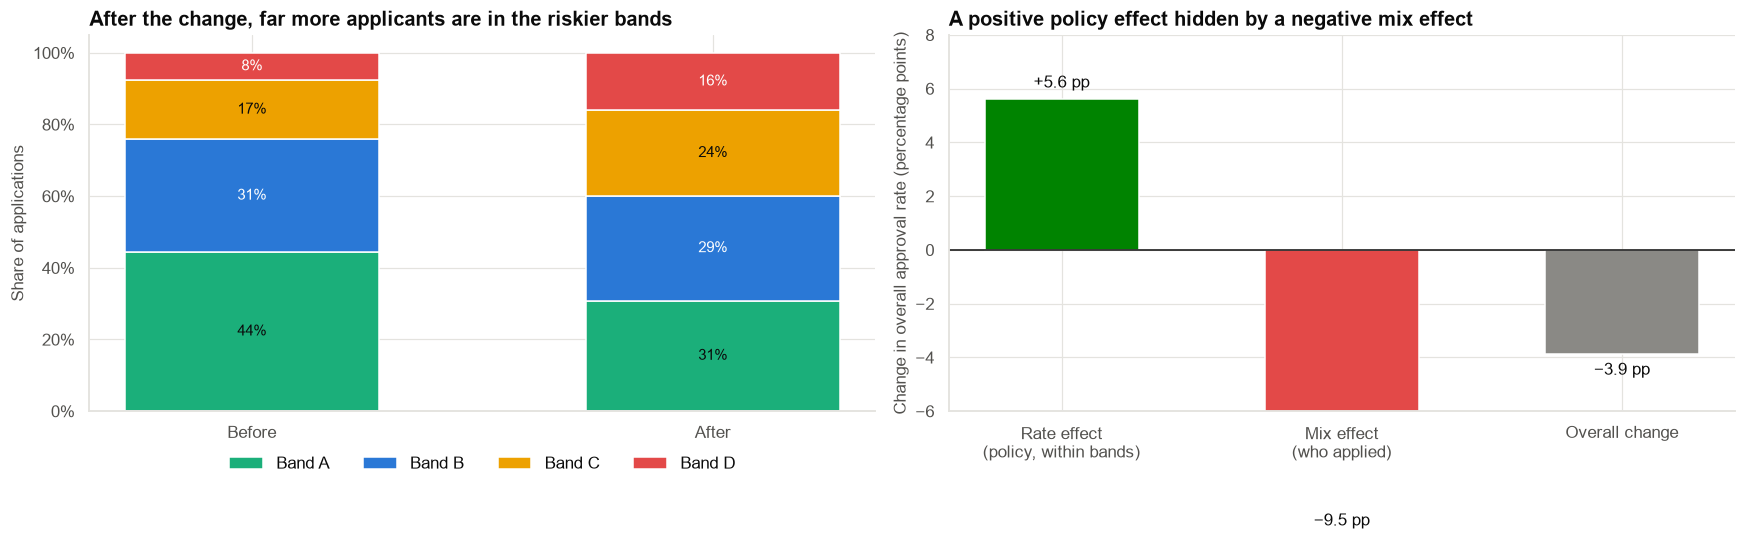

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
ax = axes[0]
bottom_b = np.zeros(2)
for b, c in zip(BANDS, [COLORS["aqua"], COLORS["blue"], COLORS["yellow"], COLORS["red"]]):
    v = np.array([mix.loc["Before", b], mix.loc["After", b]])
    ax.bar(["Before", "After"], v, bottom=bottom_b, color=c, label=f"Band {b}", width=0.55)
    for i_, (vv, bb) in enumerate(zip(v, bottom_b)):
        ax.text(i_, bb + vv / 2, f"{vv:.0%}", ha="center", va="center", fontsize=10, color="white" if b in ("B", "D") else INK)
    bottom_b += v
ax.yaxis.set_major_formatter(pctfmt)
ax.set(ylabel="Share of applications", title="After the change, far more applicants are in the riskier bands")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=4)
ax = axes[1]
vals = [100 * rate_effect.sum(), 100 * mix_effect.sum(), 100 * (rate_effect.sum() + mix_effect.sum())]
ax.bar(["Rate effect\n(policy, within bands)", "Mix effect\n(who applied)", "Overall change"], vals, color=[COLORS["green"], COLORS["red"], INK_MUTED], width=0.55)
for i_, v in enumerate(vals):
    ax.text(i_, v + (0.3 if v >= 0 else -0.3), f"{v:+.1f} pp".replace("-", "−"), ha="center", va="bottom" if v >= 0 else "top", fontsize=11)
ax.axhline(0, color=INK, lw=1)
ax.set(ylabel="Change in overall approval rate (percentage points)", title="A positive policy effect hidden by a negative mix effect")
ax.set_ylim(-6, 8)
fig.tight_layout()
save_fig(fig, "fig02_mix_and_decomposition", PATHS["figures"])
plt.show()

**Observation.** The share of applications in the **riskiest** bands (C and D) rose from about 24% to about 40%.
The overall change of −3.9 points splits **exactly** into
- a **rate effect** of about **+5.6 points** (what the policy did within bands, weighted by the average mix), and
- a **mix effect** of about **−9.5 points** (what happened because the applicant pool became riskier, weighted by
  the average approval rates).

**Interpretation.** Approval rates are far lower in the risky bands (a band-D applicant is approved about 15–20% of
the time, a band-A applicant about 90–95%). When many more applicants come from the low-approval bands, the **overall**
rate falls **even if every band is approved more often**. The paradox arises whenever the **group sizes change** and
the **group rates differ a lot**.

**The decomposition identity** (with the average of before and after weights, so that it is exact):

  Δ overall = Σ ½(w_after + w_before) × Δ rate  +  Σ ½(r_after + r_before) × Δ weight

## Section 8 — What caused the mix shift?

In [8]:
ch_mix = pd.crosstab(apps["period"], apps["channel"], normalize="index").loc[["Before", "After"]]
save_table(ch_mix, "channel_mix", PATHS["tables"])
display(ch_mix)
band_by_ch = apps.groupby(["channel", "period", "risk_band"], observed=True).size().unstack("risk_band")
band_by_ch_pct = band_by_ch.div(band_by_ch.sum(axis=1), axis=0)
save_table(band_by_ch_pct, "risk_mix_within_channel", PATHS["tables"])
display(band_by_ch_pct)
tests = []
for ch in ["Branch", "Online", "Agent"]:
    ct = pd.crosstab(apps.loc[apps["channel"] == ch, "period"], apps.loc[apps["channel"] == ch, "risk_band"])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    tests.append({"channel": ch, "χ²": chi2, "df": dof, "p_value": p})
tests = pd.DataFrame(tests).set_index("channel")
save_table(tests, "within_channel_mix_tests", PATHS["tables"])
display(tests)
agent_share = apps.groupby("period")["channel"].apply(lambda s: (s == "Agent").mean())
risky_agent = apps[apps["channel"] == "Agent"]["risk_band"].isin(["C", "D"]).mean(); risky_other = apps[apps["channel"] != "Agent"]["risk_band"].isin(["C", "D"]).mean()
print(f"Agent share of applications: {agent_share['Before']:.0%} → {agent_share['After']:.0%};  share in bands C/D: Agent {risky_agent:.0%} vs Branch+Online {risky_other:.0%}")

channel,Branch,Online,Agent
period,,,
Before,0.5013,0.3936,0.1051
After,0.3021,0.2445,0.4535


risk_band           A      B      C      D
channel period                            
Branch  After  0.4791 0.3275 0.1461 0.0472
        Before 0.4997 0.3085 0.1438 0.0480
Online  After  0.4745 0.3199 0.1541 0.0515
        Before 0.4664 0.3388 0.1431 0.0517
Agent   After  0.1051 0.2543 0.3458 0.2948
        Before 0.0960 0.2474 0.3584 0.2982

,χ²,df,p_value
channel,,,
Branch,5.2991,3,0.1512
Online,4.1867,3,0.2420
Agent,1.5943,3,0.6607


Agent share of applications: 11% → 45%;  share in bands C/D: Agent 64% vs Branch+Online 20%


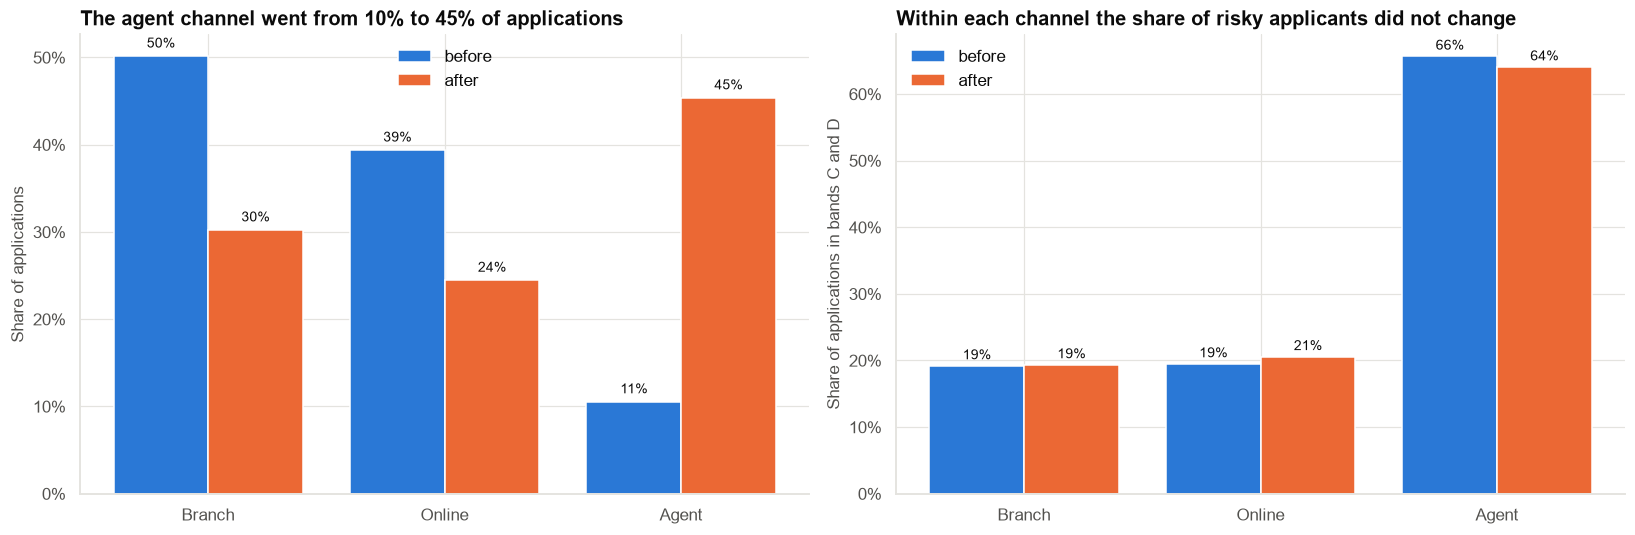

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
x = np.arange(3)
ax.bar(x - 0.2, ch_mix.loc["Before"], width=0.4, color=BEFORE, label="before"); ax.bar(x + 0.2, ch_mix.loc["After"], width=0.4, color=AFTER, label="after")
for xi, (bv, av) in enumerate(zip(ch_mix.loc["Before"], ch_mix.loc["After"])):
    ax.text(xi - 0.2, bv + 0.01, f"{bv:.0%}", ha="center", fontsize=9); ax.text(xi + 0.2, av + 0.01, f"{av:.0%}", ha="center", fontsize=9)
ax.set_xticks(x, ["Branch", "Online", "Agent"]); ax.yaxis.set_major_formatter(pctfmt)
ax.set(title="The agent channel went from 10% to 45% of applications", ylabel="Share of applications"); ax.legend(frameon=False)
ax = axes[1]
risky = apps.assign(risky=apps["risk_band"].isin(["C", "D"]).astype(int)).groupby(["channel", "period"], observed=True)["risky"].mean().unstack().loc[["Branch", "Online", "Agent"], ["Before", "After"]]
ax.bar(x - 0.2, risky["Before"], width=0.4, color=BEFORE, label="before"); ax.bar(x + 0.2, risky["After"], width=0.4, color=AFTER, label="after")
for xi, (bv, av) in enumerate(zip(risky["Before"], risky["After"])):
    ax.text(xi - 0.2, bv + 0.01, f"{bv:.0%}", ha="center", fontsize=9); ax.text(xi + 0.2, av + 0.01, f"{av:.0%}", ha="center", fontsize=9)
ax.set_xticks(x, ["Branch", "Online", "Agent"]); ax.yaxis.set_major_formatter(pctfmt)
ax.set(title="Within each channel the share of risky applicants did not change", ylabel="Share of applications in bands C and D"); ax.legend(frameon=False)
fig.tight_layout()
save_fig(fig, "fig03_channel_mix", PATHS["figures"])
plt.show()

**Observation.**
- The **agent channel** grew from about 10% to about 45% of applications.
- Agent applicants are much riskier: about 64% fall in bands C and D, against about 20% for Branch and Online.
- **Within each channel**, the risk mix is the **same** before and after (the χ² tests find no difference).

**Interpretation.** The whole shift in the risk mix is explained by **the growth of the agent channel**, not by any
change in who applies **within** a channel. The acquisition campaign (which expanded the agent network) is the
cause of the riskier mix, and it is independent of the approval policy.

## Section 9 — The right comparison: hold the mix fixed

### 9.1 Direct standardisation
Apply each period's band-specific approval rates to **one common mix** of bands. The difference then reflects **only**
the policy.

In [10]:
pooled_mix = apps["risk_band"].value_counts(normalize=True).reindex(BANDS).to_numpy()
refs = {"Before-policy mix": w0, "After-policy mix": w1, "Pooled mix (all applications)": pooled_mix}

def standardised(df, mix_):
    r_b = df[df["period"] == "Before"].groupby("risk_band", observed=True)["approved"].mean().reindex(BANDS).to_numpy()
    r_a = df[df["period"] == "After"].groupby("risk_band", observed=True)["approved"].mean().reindex(BANDS).to_numpy()
    return (mix_ * r_b).sum(), (mix_ * r_a).sum()

rows = []
boots = {k: [] for k in refs}
for _ in range(1000):
    bs = pd.concat([apps[apps["period"] == per].iloc[rng.integers(0, (apps["period"] == per).sum(), (apps["period"] == per).sum())] for per in ["Before", "After"]])
    for k, m_ in refs.items():
        s0, s1 = standardised(bs, m_)
        boots[k].append(100 * (s1 - s0))
for k, m_ in refs.items():
    s0, s1 = standardised(apps, m_)
    rows.append({"reference mix": k, "standardised approval before": s0, "standardised approval after": s1, "difference (pp)": 100 * (s1 - s0),
                 "ci_low (pp)": np.percentile(boots[k], 2.5), "ci_high (pp)": np.percentile(boots[k], 97.5)})
std = pd.DataFrame(rows).set_index("reference mix")
save_table(std, "standardised_rates", PATHS["tables"])
std

,standardised approval before,standardised approval after,difference (pp),ci_low (pp),ci_high (pp)
reference mix,,,,,
Before-policy mix,0.6958,0.7519,5.6060,4.6293,6.4793
After-policy mix,0.6008,0.6569,5.6118,4.5593,6.5317
Pooled mix (all applications),0.6430,0.6991,5.6092,4.5930,6.4381


**Observation.** Whichever fixed mix of risk bands is used, the policy raised the approval rate by about **5.6
percentage points** (95% CI about 4.6 to 6.5), a reversal of the naive −3.9.

### 9.2 Stratified odds ratio (Mantel-Haenszel) and tests across the bands

In [11]:
tabs = []
for b in BANDS:
    s = apps[apps["risk_band"] == b]
    a = s[s["period"] == "After"]["approved"]; bf = s[s["period"] == "Before"]["approved"]
    tabs.append(np.array([[a.sum(), len(a) - a.sum()], [bf.sum(), len(bf) - bf.sum()]]))
st = StratifiedTable(tabs)
mh_or = st.oddsratio_pooled; mh_ci = st.oddsratio_pooled_confint()
cmh = st.test_null_odds(correction=True)
bd = st.test_equal_odds()
band_or = [(t[0, 0] / t[0, 1]) / (t[1, 0] / t[1, 1]) for t in tabs]
mh = pd.DataFrame({"estimate": [mh_or, st.riskratio_pooled], "ci_low": [mh_ci[0], np.nan], "ci_high": [mh_ci[1], np.nan]},
                  index=["Mantel-Haenszel pooled odds ratio (after vs before)", "Mantel-Haenszel pooled risk ratio (point estimate only)"])
save_table(mh, "mantel_haenszel", PATHS["tables"])
display(mh)
print(f"Band-specific odds ratios: {', '.join(f'{b}: {o:.2f}' for b, o in zip(BANDS, band_or))}   |   crude (collapsed) odds ratio: {or_:.2f}")
print(f"Cochran-Mantel-Haenszel test of 'no association within bands': χ² = {cmh.statistic:.1f}, p = {fmt_p(cmh.pvalue)}")
print(f"Breslow-Day test that the ODDS RATIO is the same in all bands: χ² = {bd.statistic:.2f}, p = {fmt_p(bd.pvalue)}")
# The same homogeneity question on the RISK-DIFFERENCE (percentage-point) scale: Cochran's Q on the band-specific differences.
rd_b = byband["difference (pp)"].to_numpy() / 100
se_b = ((byband["ci_high (pp)"] - byband["ci_low (pp)"]) / (2 * 1.96 * 100)).to_numpy()
wq = 1 / se_b ** 2
rd_bar = (wq * rd_b).sum() / wq.sum()
Q = (wq * (rd_b - rd_bar) ** 2).sum()
p_Q = stats.chi2.sf(Q, len(rd_b) - 1)
print(f"Same question on the RISK-DIFFERENCE scale: pooled difference {100 * rd_bar:+.2f} pp; Cochran Q = {Q:.2f} on {len(rd_b) - 1} df, p = {p_Q:.2f}")

,estimate,ci_low,ci_high
Mantel-Haenszel pooled odds ratio (after vs before),1.4480,1.3593,1.5426
Mantel-Haenszel pooled risk ratio (point estimate only),1.0852,NaN,NaN


Band-specific odds ratios: A: 2.15, B: 1.38, C: 1.26, D: 1.41   |   crude (collapsed) odds ratio: 0.84
Cochran-Mantel-Haenszel test of 'no association within bands': χ² = 131.9, p = < 0.001
Breslow-Day test that the ODDS RATIO is the same in all bands: χ² = 30.59, p = < 0.001
Same question on the RISK-DIFFERENCE scale: pooled difference +5.39 pp; Cochran Q = 1.37 on 3 df, p = 0.71


**Observation.** The Mantel-Haenszel pooled odds ratio is about **1.45** (95% CI 1.36–1.54) in **favour of
approval after the policy**, against a crude (collapsed) odds ratio of 0.84. The Cochran-Mantel-Haenszel test rejects
"no association within bands" decisively.

**Is the effect the same in every band? It depends on the scale.**
- On the **odds-ratio scale**, the band-specific odds ratios are **2.15 (A), 1.38 (B), 1.26 (C), 1.41 (D)**, and the
  **Breslow-Day** test rejects equality (p < 0.001): the policy looks much "stronger" in band A.
- On the **percentage-point scale**, the band-specific changes are **+5.1, +6.4, +5.7 and +5.0 points**, and Cochran's Q
  test of equal risk differences does **not** reject (Q = 1.4 on 3 df, p = 0.71). The pooled difference is about
  **+5.4 points**.

Both statements are correct. In band A (90% approved before), a 5-point rise is a big change in the **odds** (from 9 to 1
to 19 to 1), while in band C (40% approved) the same 5 points is a small change in the odds. A constant additive
effect on probabilities **necessarily** looks like unequal odds ratios. Whether a policy effect is "the same
everywhere" is a property of the **scale** you choose; for business reporting, percentage points are usually the more
natural scale.

**The two summaries disagree because they compare different things.** The crude odds ratio compares the pooled
populations, with different mixes. The Mantel-Haenszel estimate compares **like with like** within bands and then
averages the band-level comparisons.

### 9.3 Regression adjustment

In [12]:
m_crude = smf.logit("approved ~ after", apps).fit(disp=0)
m_band = smf.logit("approved ~ after + C(risk_band)", apps).fit(disp=0)
m_chan = smf.logit("approved ~ after + C(risk_band) + C(channel)", apps).fit(disp=0)
m_int = smf.logit("approved ~ after * C(risk_band)", apps).fit(disp=0)
lr = 2 * (m_int.llf - m_band.llf)
reg = pd.DataFrame({"odds ratio for 'after'": [np.exp(m.params["after"]) for m in (m_crude, m_band, m_chan)],
                    "ci_low": [np.exp(m.conf_int().loc["after", 0]) for m in (m_crude, m_band, m_chan)],
                    "ci_high": [np.exp(m.conf_int().loc["after", 1]) for m in (m_crude, m_band, m_chan)],
                    "p_value": [m.pvalues["after"] for m in (m_crude, m_band, m_chan)]},
                   index=["crude: approved ~ after", "adjusted for risk band", "adjusted for risk band and channel"])
save_table(reg, "logistic_adjustment", PATHS["tables"])
display(reg)
print(f"Does the policy effect differ by band? Likelihood-ratio test of the interaction: χ² = {lr:.2f} on 3 df, p = {fmt_p(stats.chi2.sf(lr, 3))}")
print("Channel odds ratios vs Branch, with risk band in the model:", {k.split('[T.')[1].rstrip(']'): round(np.exp(v), 2) for k, v in m_chan.params.items() if 'channel' in k},
      "→ p-values", {k.split('[T.')[1].rstrip(']'): round(m_chan.pvalues[k], 2) for k in m_chan.params.index if 'channel' in k})

,odds ratio for 'after',ci_low,ci_high,p_value
crude: approved ~ after,0.8370,0.7951,0.8813,0.0000
adjusted for risk band,1.4469,1.3584,1.5412,0.0000
adjusted for risk band and channel,1.4516,1.3564,1.5534,0.0000


Does the policy effect differ by band? Likelihood-ratio test of the interaction: χ² = 31.31 on 3 df, p = < 0.001
Channel odds ratios vs Branch, with risk band in the model: {'Online': np.float64(1.03), 'Agent': np.float64(1.0)} → p-values {'Online': np.float64(0.51), 'Agent': np.float64(0.97)}


**Observation.** The crude logistic regression reproduces the naive result (odds ratio below 1). Adding **risk
band** reverses it (odds ratio about 1.5). Adding **channel** as well changes nothing: once the risk band is known, the
channel adds no information about approval. The logistic interaction test (odds-ratio scale) does detect that the
odds ratio differs by band, for the reason explained above; on the percentage-point scale there is no such evidence.

## Section 10 — Which comparison is right? It depends on the causal story

A statistical rule ("always stratify") is not enough. Whether to compare within groups or overall depends on
**why** the group mix changed. Two stories fit the same table:

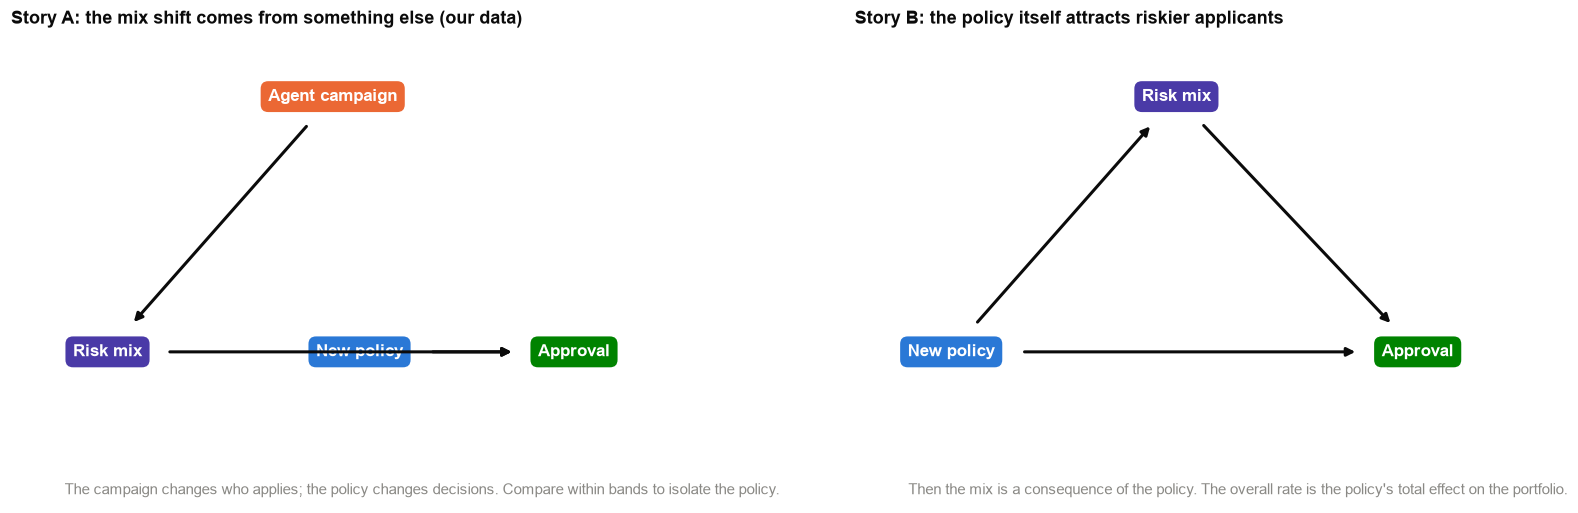

In [13]:
def draw_dag(ax, nodes, edges, title, note):
    for name, (x, y, col) in nodes.items():
        ax.text(x, y, name, ha="center", va="center", fontsize=11, fontweight="bold", color="white", bbox=dict(boxstyle="round,pad=0.45", fc=col, ec="none"))
    for a, b_ in edges:
        (x1, y1, _), (x2, y2, _) = nodes[a], nodes[b_]
        sa = 3.6 * len(a) + 12 if y1 == y2 else 26
        sb = 3.6 * len(b_) + 12 if y1 == y2 else 26
        ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-|>", lw=2, color=INK, shrinkA=sa, shrinkB=sb))
    ax.set_xlim(-0.1, 1.1); ax.set_ylim(-0.2, 1.05); ax.axis("off")
    ax.set_title(title, loc="left", fontsize=12, fontweight="bold")
    ax.text(0.0, -0.15, note, fontsize=9.5, color=INK_MUTED, va="top")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
draw_dag(axes[0], {"Agent campaign": (0.5, 0.88, COLORS["orange"]), "Risk mix": (0.08, 0.2, COLORS["violet"]), "New policy": (0.55, 0.2, COLORS["blue"]), "Approval": (0.95, 0.2, COLORS["green"])},
         [("Agent campaign", "Risk mix"), ("Risk mix", "Approval"), ("New policy", "Approval")],
         "Story A: the mix shift comes from something else (our data)", "The campaign changes who applies; the policy changes decisions. Compare within bands to isolate the policy.")
draw_dag(axes[1], {"New policy": (0.08, 0.2, COLORS["blue"]), "Risk mix": (0.5, 0.88, COLORS["violet"]), "Approval": (0.95, 0.2, COLORS["green"])},
         [("New policy", "Risk mix"), ("Risk mix", "Approval"), ("New policy", "Approval")],
         "Story B: the policy itself attracts riskier applicants", "Then the mix is a consequence of the policy. The overall rate is the policy's total effect on the portfolio.")
fig.tight_layout()
save_fig(fig, "fig04_causal_stories", PATHS["figures"])
plt.show()

| | Story A (mix shift is external) | Story B (mix shift is caused by the policy) |
|---|---|---|
| Example | A new agent network started in the same month | A looser policy attracts riskier applicants |
| Question answered by **within-band** comparison | "What did the policy do to the decision rule?" | The direct effect only, not the total |
| Question answered by the **overall** comparison | Mixes the policy with the campaign: misleading | "What happened to the portfolio's approval rate overall?" |
| Evidence in our data | The shift is **entirely** through the Agent channel growth; the risk mix **within** each channel did not change; the campaign started in April | Would require applicants to be riskier **within** channels after the policy |

**Our data support story A.** The risk mix within channels is unchanged, and the shift tracks the growth of the agent
channel, so the policy-specific question is answered by the **within-band (standardised) comparison**: approval
rose by about 5 to 6 points.

**What would change the conclusion?** If the policy itself attracted agent applicants (for instance, by promoting
"easier approval" in agent materials), the policy and the mix would be entangled. The right comparison for the **total
effect on the portfolio** would then be the overall rate. A before-and-after table cannot settle this by statistics
alone: it needs **timing data** (when did the campaign start?) and **process knowledge**.

> **Stratification adjusts for what is measured.** It cannot remove other differences between the two periods:
> seasonality, a change in the scorecard, other campaigns. A before/after comparison is not an experiment (Case 21).

## Section 11 — Decision framework: spotting and handling Simpson's paradox

| Symptom or question | What to do |
|---|---|
| An overall trend disagrees with the trend in every subgroup | Simpson's paradox: **find the variable that changed the group mix** |
| Group sizes changed between the periods you compare | Decompose the change into a **rate** part and a **mix** part |
| Group rates differ a lot (high-risk vs low-risk) | Mix effects can be large: always report **by group** and **standardised** |
| You want "the effect of the policy" | Compare **within** groups defined **before** the policy, and standardise to a fixed mix |
| The mix shift may be **caused by** the intervention | The overall rate is the **total** effect; within-group effects are the **direct** effect. Report both |
| Subgroup effects differ (Breslow-Day / interaction rejects) | Check **which scale**: odds ratios can differ when percentage-point effects are constant (and vice versa). Report in the scale the decision uses |
| Adjustment variable is a **consequence** of the treatment (mediator) or a collider | **Do not adjust** (Cases 07, 08, 21) |
| Only two periods, no control group | Say so: adjusting for measured bands does not remove time effects. Seek a control group or a staged roll-out |

**Choosing the stratification variable**: use variables that (a) **precede** the intervention, (b) affect the
outcome, and (c) differ in distribution between the groups. Risk band qualifies; **default after approval** or
**loan amount chosen after approval** would not.

**How to report:** show the aggregate **and** the by-group rates side by side, name the variable that explains the
reversal, and give the standardised comparison.

## Section 12 — Results

In [14]:
summary = pd.DataFrame({"Value": [
    f"{k0 / n0:.1%} → {k1 / n1:.1%}: {100 * d_:+.1f} pp (95% CI {100 * lo_:+.1f} to {100 * hi_:+.1f}); OR {or_:.2f}".replace("-", "−"),
    f"A {byband.loc['A', 'difference (pp)']:+.1f}, B {byband.loc['B', 'difference (pp)']:+.1f}, C {byband.loc['C', 'difference (pp)']:+.1f}, D {byband.loc['D', 'difference (pp)']:+.1f} pp (all p ≤ 0.001)",
    f"share in bands C/D {(w0[2:].sum()):.0%} → {(w1[2:].sum()):.0%};  rate effect {100 * rate_effect.sum():+.1f} pp, mix effect {100 * mix_effect.sum():+.1f} pp".replace("-", "−"),
    f"Agent channel {ch_mix.loc['Before', 'Agent']:.0%} → {ch_mix.loc['After', 'Agent']:.0%}; within-channel risk mix unchanged (p = {tests['p_value'].min():.2f}–{tests['p_value'].max():.2f})",
    f"{std.iloc[0]['difference (pp)']:+.1f} pp (before mix), {std.iloc[1]['difference (pp)']:+.1f} pp (after mix); CI {std.iloc[2]['ci_low (pp)']:+.1f} to {std.iloc[2]['ci_high (pp)']:+.1f}",
    f"Mantel-Haenszel OR {mh_or:.2f} (95% CI {mh_ci[0]:.2f}–{mh_ci[1]:.2f}); Breslow-Day p {fmt_p(bd.pvalue)} (odds-ratio scale), Cochran Q p = {p_Q:.2f} (risk-difference scale); logistic OR {reg.iloc[1, 0]:.2f} (band-adjusted)",
]}, index=["Overall", "Within bands", "Decomposition", "Cause of mix shift", "Standardised", "Stratified / adjusted"])
save_table(summary, "results_summary", PATHS["tables"])
summary

,Value
Overall,69.6% → 65.7%: −3.9 pp (95% CI −5.0 to −2.8); ...
Within bands,"A +5.1, B +6.4, C +5.7, D +5.0 pp (all p ≤ 0.001)"
Decomposition,share in bands C/D 24% → 40%; rate effect +5....
Cause of mix shift,Agent channel 11% → 45%; within-channel risk m...
Standardised,"+5.6 pp (before mix), +5.6 pp (after mix); CI ..."
Stratified / adjusted,Mantel-Haenszel OR 1.45 (95% CI 1.36–1.54); Br...


## Section 13 — Interpretation

- **The overall decline is a mix effect, not a stricter policy.** Within every risk band, approvals rose by about 5–6
  points. The overall rate fell because the riskiest applicants (from the new agent channel) became a much bigger share
  of the pool.
- **The new policy is more generous, as Credit Policy claims.** At a fixed mix, approval is up by about 5.6 points.
- **The paradox has a cause we can name and check:** the agent campaign. The risk mix within channels did not change.
- **What this does not tell us:** whether the extra approvals are **good** (do approved loans repay?), and whether
  anything else changed between the periods.

## Section 14 — What can we say?

| ✅ We can say | ❌ We cannot say |
|---|---|
| "Overall approval fell 3.9 points because the applicant pool became riskier." | "The new policy reduced approvals." |
| "At the same risk level, approval rose by about 5–6 points in every band." | "The policy caused the 5.5-point rise" (before/after, not randomised; time effects remain possible). |
| "The shift in mix is entirely due to growth of the agent channel." | "The agent channel is bad." (It brings riskier applicants, which is a business choice, not a flaw.) |
| "The policy is more generous at every risk level." | "More approvals are better." (Default outcomes are not analysed here.) |

## Section 15 — Business interpretation

- **Reporting:** show approval rates **by risk band** and the **mix**, alongside the overall rate, every quarter. A
  dashboard with only the overall rate will mislead after any mix change.
- **Policy:** the policy did what it was designed to do. The **portfolio** consequence of the agent campaign
  (a riskier book) needs monitoring on **default outcomes**, not on approval rates.
- **Communication:** brief the Chief Risk Officer with the decomposition: **+5.6 points from policy, −9.5 points from
  who applied**.

## Section 16 — Limitations

- A before/after comparison has no control group: seasonality or other simultaneous changes are not ruled out.
- Risk bands are coarse; within-band risk may still have shifted (a finer scorecard could change the picture).
- Approval is not the same as **good** approval: no default data here.
- Synthetic data with a known structure.

## Section 17 — Final recommendation

> **Do not roll back the new policy.** Report approval **by risk band** and **standardised to a fixed mix**: the policy
> raised approvals by about 5–6 points at every risk level; the overall decline reflects the riskier applicant mix from
> the agent campaign. Add a **default-rate monitor by channel and band** to find out whether the extra approvals are
> sound, and run any future policy change as a **staged roll-out with a control group**.

## Section 18 — What would I do next?

1. Link approvals to **12-month default** and compare default rates by band, channel and period (Case 27).
2. Run the next policy change as a **randomised or staggered roll-out** (a control group removes the time effect).
3. Build a **monthly "rate and mix" dashboard** that shows the decomposition automatically.
4. Re-check the paradox with a **finer risk score** (e.g. 10 bands) and with other variables (income, product).
5. Continue to **Case 21** (does cashback reduce churn? association vs causation).